## 1. 프로젝트 개요 
- 프로젝트명: 
    **불량 선별 실적 시계열 분석**
    (Defect-Sorting-Performance-Analysis)
- 분석 기간: 2025년 8월 ~ 2026년 3월
- 분석 목적: 선별 실적에서 유의미한 추이 및 패턴을 도출한다.
- 분석 질문:
 1) 시간에 따른 처리 실적은 어떻게 변화하는가?
 2) 품종에 따른 실적의 변화에 패턴이 있는가?
 3) 처리 대상인 불량유형 구성비의 변화가 있는가? 

## 2. 기본 설정 및 원본 파일 내용 확인

- 기본 라이브러리 import, 그래프 크기/스타일을 미리 설정한다. 
- 원본 엑셀 파일을 불러와 데이터 구조를 확인한다.
- 시트 목록과 각 시트의 데이터 내용을 확인한다.  
- 표를 구성하는 칼럼명을 확인한다.   

In [23]:
# 기본 설정
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")

In [24]:
# 원본 엑셀 파일(RAW_data.xlsx) 읽기
df = pd.read_excel("./data/RAW_data.xlsx")
df.head()

,구분,반,작업일,품종,Lot 코드,불량유형,처리 수량(BOX)
0,8월 1주차,오전,25.08.04,B,K5KKK1,홀 이상,4.0
1,8월 1주차,오전,25.08.05,B,K5KKK1,홀 이상,4.0
2,8월 1주차,오전,25.08.05,B,K5KKK2,홀 이상,2.0
3,8월 1주차,오후,25.08.05,B,K5KKK2,홀 이상,3.0
4,8월 1주차,오전,25.08.06,B,K5KKK2,홀 이상,3.0


In [25]:
# 시트 목록 확인

import pandas as pd

file_path = "./data/RAW_data.xlsx"

xls = pd.ExcelFile(file_path)
xls.sheet_names

['선별실적', '인원관리']

In [26]:
# 시트별 데이터 불러오기 

df_perf = pd.read_excel(file_path, sheet_name="선별실적")
df_worker = pd.read_excel(file_path, sheet_name="인원관리")

# 데이터 확인

display(df_perf.head())
display(df_worker.head())

print(df_perf.shape)
print(df_worker.shape)

c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


,구분,반,작업일,품종,Lot 코드,불량유형,처리 수량(BOX)
0,8월 1주차,오전,25.08.04,B,K5KKK1,홀 이상,4.0
1,8월 1주차,오전,25.08.05,B,K5KKK1,홀 이상,4.0
2,8월 1주차,오전,25.08.05,B,K5KKK2,홀 이상,2.0
3,8월 1주차,오후,25.08.05,B,K5KKK2,홀 이상,3.0
4,8월 1주차,오전,25.08.06,B,K5KKK2,홀 이상,3.0


,작업일,반,인원수
0,25.08.04,오전,5.0
1,25.08.05,오전,6.0
2,25.08.05,오후,6.0
3,25.08.06,오전,6.0
4,25.08.06,오후,6.0


(420, 7)
(241, 3)


In [27]:
# 칼럼명 확인 및 정리

print(df_perf.columns.tolist())
print(df_worker.columns.tolist())

df_perf.columns = df_perf.columns.str.strip()
df_worker.columns = df_worker.columns.str.strip()

['구분', '반', '작업일', '품종', 'Lot 코드', '불량유형', '처리 수량(BOX)']
['작업일', '반', '인원수']


## 3. 데이터 전처리(1차)
- 날짜형 변환
- 수치형 변환
- 결측치 확인 및 중복 제거
- 파생변수 생성(연도, 월, 주차)
- 인원수 데이터 merge
    - 작업일+반 기준으로 시트 1 내용에 병합 

In [28]:
# 날짜형 변환

df_perf["작업일"] = pd.to_datetime(df_perf["작업일"], format="%y.%m.%d", errors="coerce")
df_worker["작업일"] = pd.to_datetime(df_worker["작업일"], format="%y.%m.%d", errors="coerce")

display(df_perf[["작업일"]].head())
display(df_worker[["작업일"]].head())

,작업일
0,2025-08-04
1,2025-08-05
2,2025-08-05
3,2025-08-05
4,2025-08-06


,작업일
0,2025-08-04
1,2025-08-05
2,2025-08-05
3,2025-08-06
4,2025-08-06


In [29]:
# 수치형 변환

df_perf["처리 수량(BOX)"] = pd.to_numeric(df_perf["처리 수량(BOX)"], errors="coerce")
df_worker["인원수"] = pd.to_numeric(df_worker["인원수"], errors="coerce")

In [30]:
# 결측치 확인

print(df_perf.isnull().sum())
print(df_worker.isnull().sum())

구분            0
반             0
작업일           0
품종            0
Lot 코드        0
불량유형          0
처리 수량(BOX)    0
dtype: int64
작업일    0
반      0
인원수    0
dtype: int64


In [31]:
# 중복 확인 및 제거

print("실적 데이터 중복 수:", df_perf.duplicated().sum())
print("인원수 데이터 중복 수:", df_worker.duplicated().sum())

df_perf = df_perf.drop_duplicates()
df_worker = df_worker.drop_duplicates()

실적 데이터 중복 수: 0
인원수 데이터 중복 수: 2


In [32]:
# 파생변수 생성 전 추가 사전 작업 

## 날짜형 통일
df_perf["작업일"] = pd.to_datetime(df_perf["작업일"]).dt.normalize()
df_worker["작업일"] = pd.to_datetime(df_worker["작업일"]).dt.normalize()

## df_perf의 작업일-구분 기준표
date_map = df_perf[["작업일", "구분"]].drop_duplicates()

## df_worker에 구분 붙이기
df_worker = df_worker.merge(date_map, on="작업일", how="left")

# 파생변수 생성 및 확인
df_perf["연도"] = df_perf["작업일"].dt.year
df_perf["월"] = df_perf["구분"].str.extract(r"(\d+)월").astype(int)
df_perf["주차"] = df_perf["구분"].str.extract(r"(\d+)주차").astype(int)

df_worker["연도"] = df_worker["작업일"].dt.year
df_worker["월"] = df_worker["구분"].str.extract(r"(\d+)월").astype(int)
df_worker["주차"] = df_worker["구분"].str.extract(r"(\d+)주차").astype(int)

print(df_perf[["작업일", "구분", "연도", "월", "주차"]].head())
print(df_worker[["작업일", "구분", "연도", "월", "주차"]].head())
print("df_worker 구분 결측치 수:", df_worker["구분"].isna().sum())

         작업일      구분    연도  월  주차
0 2025-08-04  8월 1주차  2025  8   1
1 2025-08-05  8월 1주차  2025  8   1
2 2025-08-05  8월 1주차  2025  8   1
3 2025-08-05  8월 1주차  2025  8   1
4 2025-08-06  8월 1주차  2025  8   1
         작업일      구분    연도  월  주차
0 2025-08-04  8월 1주차  2025  8   1
1 2025-08-05  8월 1주차  2025  8   1
2 2025-08-05  8월 1주차  2025  8   1
3 2025-08-06  8월 1주차  2025  8   1
4 2025-08-06  8월 1주차  2025  8   1
df_worker 구분 결측치 수: 0


In [33]:
# 인원수 데이터 merge

df = pd.merge(
    df_perf,
    df_worker[["작업일", "반", "인원수"]],
    on=["작업일", "반"],
    how="left"
)

display(df.head())
print(df.shape)

,구분,반,작업일,품종,Lot 코드,불량유형,처리 수량(BOX),연도,월,주차,인원수
0,8월 1주차,오전,2025-08-04,B,K5KKK1,홀 이상,4.0,2025,8,1,5.0
1,8월 1주차,오전,2025-08-05,B,K5KKK1,홀 이상,4.0,2025,8,1,6.0
2,8월 1주차,오전,2025-08-05,B,K5KKK2,홀 이상,2.0,2025,8,1,6.0
3,8월 1주차,오후,2025-08-05,B,K5KKK2,홀 이상,3.0,2025,8,1,6.0
4,8월 1주차,오전,2025-08-06,B,K5KKK2,홀 이상,3.0,2025,8,1,6.0


(420, 11)


## 4. 전처리 결과 확인
전처리 이후 데이터의 형태, 최종 결측치, 기초 통계 정보를 확인한다.

In [34]:
# 최종 데이터 형태(merge 결과 포함) 확인

df.head()

print("최종 데이터 크기:", df.shape)

최종 데이터 크기: (420, 11)


In [35]:
# 최종 결측치 확인

df.isnull().sum()

구분            0
반             0
작업일           0
품종            0
Lot 코드        0
불량유형          0
처리 수량(BOX)    0
연도            0
월             0
주차            0
인원수           4
dtype: int64

In [36]:
# 데이터 정보 확인(각 컬럼 타입/null 개수/전체 행 개수)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   구분          420 non-null    str           
 1   반           420 non-null    str           
 2   작업일         420 non-null    datetime64[us]
 3   품종          420 non-null    str           
 4   Lot 코드      420 non-null    str           
 5   불량유형        420 non-null    str           
 6   처리 수량(BOX)  420 non-null    float64       
 7   연도          420 non-null    int32         
 8   월           420 non-null    int64         
 9   주차          420 non-null    int64         
 10  인원수         416 non-null    float64       
dtypes: datetime64[us](1), float64(2), int32(1), int64(2), str(5)
memory usage: 34.6 KB


## 5. 데이터 전처리(2차)
- 1차 전처리 결과 대부분의 컬럼은 결측치가 관찰되지 않았으나, 시트 2의 인원수 컬럼에서 4건의 결측이 확인되었다.
- 원본 파일 확인시 해당 인원수 값이 모두 존재하여, 결측의 원인은 실제 값 누락이 아니라 병합 키(작업일, 반)의 형식 또는 표기 불일치로 판단했다.
- 따라서 병합 키를 정규화한 후, 인원수 테이블을 재병합 실시하는 방법으로 문제를 해결했다. 

In [37]:
# 결측치 발생 행의 정보 확인
df[df['인원수'].isnull()][['작업일', '반', '구분', '품종', '처리 수량(BOX)']]

,작업일,반,구분,품종,처리 수량(BOX)
169,2025-11-05,오전,11월 1주차,A,7.0
194,2025-11-19,오전,11월 3주차,A,5.0
196,2025-11-20,오전,11월 3주차,A,2.0
214,2025-12-01,오전,12월 1주차,B,5.0


In [38]:
# 작업일 정보 형식 재통일 및 앞 뒤 공백 제거

df['작업일'] = pd.to_datetime(df['작업일'], errors='coerce').dt.normalize()
df['반'] = df['반'].astype(str).str.strip()


df_worker['작업일'] = pd.to_datetime(df_worker['작업일'], errors='coerce').dt.normalize()
df_worker['반'] = df_worker['반'].astype(str).str.strip()

In [39]:
# 재병합

df = df.merge(
    df_worker[['작업일', '반', '인원수']],
    on=['작업일', '반'],
    how='left'
)

In [40]:
# 결측치 재확인
df.isnull().sum()

구분            0
반             0
작업일           0
품종            0
Lot 코드        0
불량유형          0
처리 수량(BOX)    0
연도            0
월             0
주차            0
인원수_x         4
인원수_y         0
dtype: int64

## 6-1. 일별 처리 실적 및 3일 이동평균 분석
- 기법: **이동평균**(일별 처리 실적 합계를 기준으로 최근 3개 작업일의 평균) / 꺾은선 그래프
- 목적: 전체 추세 파악


In [41]:
# 집계 코드

daily_boxes = df.groupby('작업일', as_index=False)['처리 수량(BOX)'].sum()
daily_boxes = daily_boxes.sort_values('작업일')
daily_boxes['3일이동평균'] = daily_boxes['처리 수량(BOX)'].rolling(window=3, min_periods=1).mean()

daily_boxes.head()

,작업일,처리 수량(BOX),3일이동평균
0,2025-08-04,4.0,4.000000
1,2025-08-05,9.0,6.500000
2,2025-08-06,19.0,10.666667
3,2025-08-07,16.0,14.666667
4,2025-08-11,12.0,15.666667


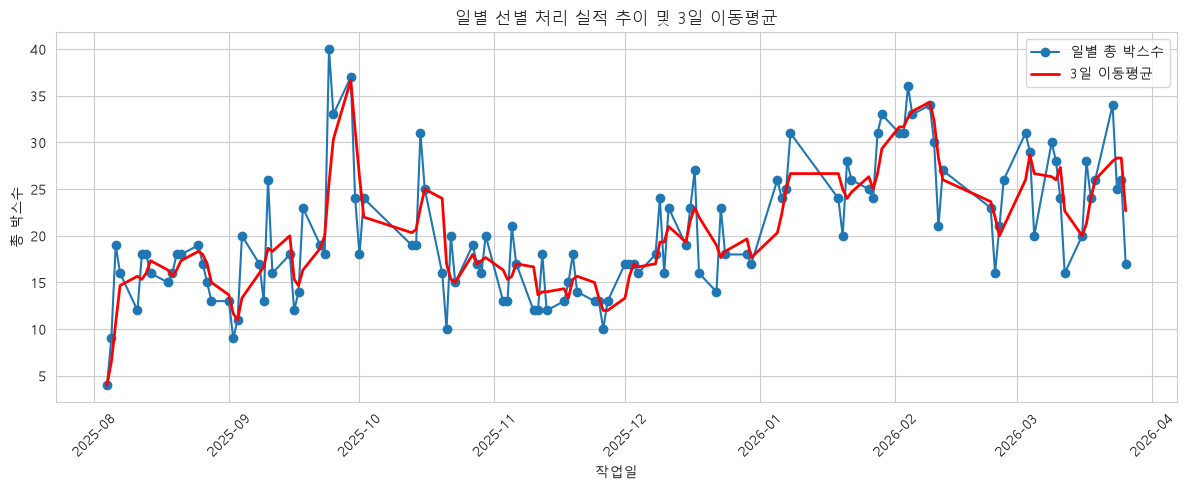

In [59]:
# 그래프 코드

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(12, 5))

plt.plot(daily_boxes['작업일'], daily_boxes['처리 수량(BOX)'], marker='o', label='일별 총 박스수')
plt.plot(daily_boxes['작업일'], daily_boxes['3일이동평균'], color='red', linewidth=2, label='3일 이동평균')

plt.title('일별 선별 처리 실적 추이 및 3일 이동평균')
plt.xlabel('작업일')
plt.ylabel('총 박스수')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- 관찰 결과
    - **일별 처리 실적선**
        - 전체 기간 동안 10~35박스 사이에서 변동
        - 최저 실적은 25년 8월 초 부근의 4박스, 최고 실적은 25년 9월 말 부근의 약 40박스
        - 25년 9월에는 실적의 변동폭이 비교적 크고, 말에는 연속해서 37~40박스 안팎의 높은 실적을 보임.
        - 25년 10월 중하순부터 11월까지는 10박스대 중반~20박스 초반 정도의 실적이 상대적으로 자주 나타남.
        - 25년 11월 말에는 약 10박스 수준의 낮은 값이 보이나, 12월부터 다시 15~25박스 수준의 실적으로 회복. 
        - 26년 1월부터는 20박스대 중반 이상의 실적이 이전보다 더 자주 나타난다.
        - 26년 2월 초에는 30박스대 중반 수준의 높은 실적을 유지 
        - 2월 중순 부터 3월까지 20박스 안팎부터 30박스 전후 값이 오르내리는 모습이 반복적으로 나타남.
        - 26년 3월 하순에는 최대 약 34박스 수준의 높은 실적을 보인 뒤, 약 17박스 수준으로 마무리 됨.

    - **3일 이동평균선** 
        - 일별 실적 대비 변동이 완만하게 나타남.(노이즈 제거 효과)
        - 25년 8월 초에는 낮은 수준에서 시작해 8월 중순까지 상승하는 모습을 보임.
        - 25년 9월 말에는 일별 처리 실적과 동반 성장하며, 전체 기간 중 높은 수준의 실적 구간 중 하나를 형성
        - 25년 10월 중순부터 11월 말까지는 이동평균선이 대체로 10박스대 중반~20박스 초반 수준에 머무름.
        - 25년 12월 이후 이동평균선은 다시 상승하는 흐름을 보이며, 1월 말 부근에서 30박스 안팎의 높은 수준에 도달
        - 26년 2월 중순 이후에는 다소 내려갔다가, 3월에 다시 20박스대 중후반 수준을 오르내림.

## 6-2 주간 선별 처리 실적 분석
- 기법: 구간별 집계 / 꺾은선 그래프
- 목적: 일별 변동을 줄여 흐름 확인


In [46]:
# 집계 코드

import pandas as pd

#분석용 데이터 복사
data = df.copy()

#작업일 datetime 변환
data['작업일'] = pd.to_datetime(data['작업일'])

#구분별 총 박스수 집계
weekly_box = (
    data.groupby('구분', as_index=False)
        .agg(
            weekly_total_boxes=('처리 수량(BOX)', 'sum'),
            start_date=('작업일', 'min')
        )
        .sort_values('start_date')
        .reset_index(drop=True)
)

print(weekly_box)

         구분  weekly_total_boxes start_date
0    8월 1주차                48.0 2025-08-04
1    8월 2주차                64.0 2025-08-11
2    8월 3주차                67.0 2025-08-18
3    8월 4주차                64.0 2025-08-25
4    9월 1주차                53.0 2025-09-01
5    9월 2주차                72.0 2025-09-08
6    9월 3주차                67.0 2025-09-15
7    9월 4주차               110.0 2025-09-22
8   10월 1주차               103.0 2025-09-29
9   10월 2주차                94.0 2025-10-13
10  10월 3주차                61.0 2025-10-20
11  10월 4주차                72.0 2025-10-27
12  11월 1주차                64.0 2025-11-03
13  11월 2주차                54.0 2025-11-10
14  11월 3주차                60.0 2025-11-17
15  11월 4주차                49.0 2025-11-24
16  12월 1주차                67.0 2025-12-01
17  12월 2주차                81.0 2025-12-08
18  12월 3주차                85.0 2025-12-15
19  12월 4주차                55.0 2025-12-22
20  12월 5주차                35.0 2025-12-29
21   1월 2주차               106.0 2026-01-05
22   1월 4주차

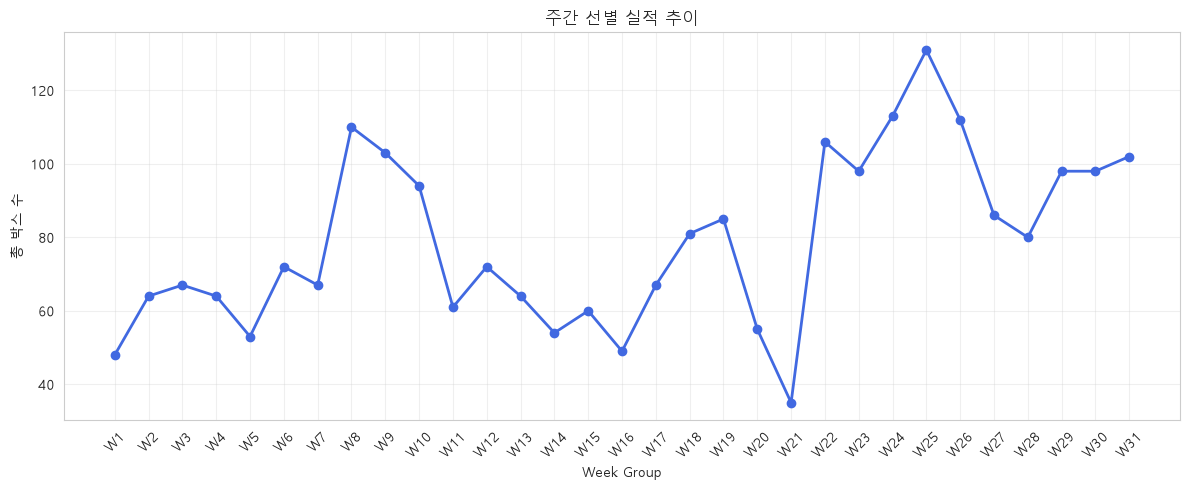

In [58]:
# 그래프 코드

import matplotlib.pyplot as plt

plt.rcParams['axes.unicode_minus'] = False

weekly_box = weekly_box.copy()
weekly_box['week_label'] = ['W' + str(i+1) for i in range(len(weekly_box))]

plt.figure(figsize=(12, 5))
plt.plot(
    weekly_box['week_label'],
    weekly_box['weekly_total_boxes'],
    marker='o',
    linewidth=2,
    color='royalblue'
)

plt.title('주간 선별 실적 추이')
plt.xlabel('Week Group')
plt.ylabel('총 박스 수')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- 관찰 결과
    - 집계 범위는 약 31주간(W1 ~ W31)
    - 전체 실적은 주별 최소 35 ~ 최대 130 박스 수준에서 변동
    - 실적이 가장 낮은 지점은 W21, 가장 높은 지점은 W25
    - 그래프 전반에 실적 상승과 하락이 반복되는 형태 
    - 중간중간 변동 폭이 큰 구간이 있으며, 특히 W21 → W22 구간이 눈에 띔.
    - 실행 초반(W1~W7)보다 후반(W22 이후) 실적값이 상대적으로들이 높음.

## 6-3. 월간 실적 비교 분석
- 기법: 구간별 집계 / 막대그래프
- 목적: 월 단위 실적 처리 규모 비교

In [50]:
# 집계 코드

import pandas as pd

#원본 복사
data = df.copy()

#날짜형 변환
data['작업일'] = pd.to_datetime(data['작업일'])

#연-월 기준 생성 (연도 경계 포함 정렬용)
data['year_month'] = data['작업일'].dt.to_period('M')

#월별 총 박스수 집계
monthly_box = (
    data.groupby('year_month', as_index=False)
        .agg(monthly_total_boxes=('처리 수량(BOX)', 'sum'))
        .sort_values('year_month')
        .reset_index(drop=True)
)

#그래프용 라벨
monthly_box['month_label'] = monthly_box['year_month'].astype(str)

monthly_box

,year_month,monthly_total_boxes,month_label
0,2025-08,243.0,2025-08
1,2025-09,363.0,2025-09
2,2025-10,269.0,2025-10
3,2025-11,227.0,2025-11
4,2025-12,323.0,2025-12
5,2026-01,317.0,2026-01
6,2026-02,329.0,2026-02
7,2026-03,378.0,2026-03


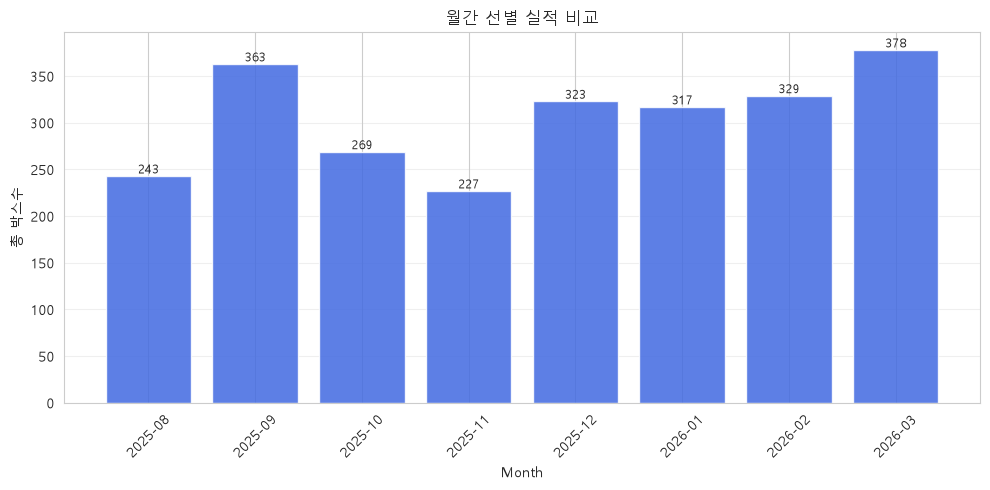

In [57]:
# 그래프 코드

import matplotlib.pyplot as plt

plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(10, 5))

bars = plt.bar(
    monthly_box['month_label'],
    monthly_box['monthly_total_boxes'],
    color='royalblue',
    alpha=0.85
)

#막대 위에 수량 표시 추가
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{int(height):,}',   # 천 단위 콤마 표시
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.title('월간 선별 실적 비교')
plt.xlabel('Month')
plt.ylabel('총 박스수')
plt.grid(axis='y', alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- 관찰 결과
    - 분석 기간은 2025-08부터 2026-03까지 총 8개월간
    - 월별 실적은 최저 227박스(25년 11월)에서 최고 378박스(26년 3월)사이를 변동
    - 26년 들어(약 3개월간) 모든 월 300박스 이상 실적을 달성했다. 
    - 25년에는 9월과 12월을 제외하고 300박스 이상 실적을 달성하지 못했다.

## 6-4. 품종별 실적 추이 분석(주단위)
- 기법: 구간별 집계 / 히트맵
- 목적: 품종별 실적 패턴 차이 확인

In [ ]:
# 집계 코드

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#품종 순서 고정
variety_order = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']

#week_order는 앞에서 만든 주차 순서표 사용
week_labels = week_order['week_label'].tolist()

#히트맵용 피벗 테이블
heatmap_df = (
    weekly_variety_box
    .pivot(index='품종', columns='week_label', values='total_boxes')
    .reindex(index=variety_order, columns=week_labels)
)

heatmap_df
   

week_label,W1,W2,W3,W4,W5,W6,W7,W8,W9,W10,...,W22,W23,W24,W25,W26,W27,W28,W29,W30,W31
품종,,,,,,,,,,,,,,,,,,,,,
A,NaN,64.0,67.0,64.0,53.0,30.0,NaN,NaN,10.0,20.0,...,NaN,20.0,42.0,99.0,63.0,17.0,80.0,15.0,55.0,40.0
B,24.0,NaN,NaN,NaN,NaN,NaN,67.0,110.0,76.0,74.0,...,104.0,23.0,25.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
C,24.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
D,NaN,NaN,NaN,NaN,NaN,42.0,NaN,NaN,17.0,NaN,...,2.0,50.0,NaN,19.0,17.0,48.0,NaN,57.0,32.0,49.0
E,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,5.0,3.0,13.0,32.0,21.0,NaN,6.0,NaN,NaN
F,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,11.0,NaN
G,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.0
H,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,43.0,NaN,NaN,NaN,NaN,14.0,NaN,NaN


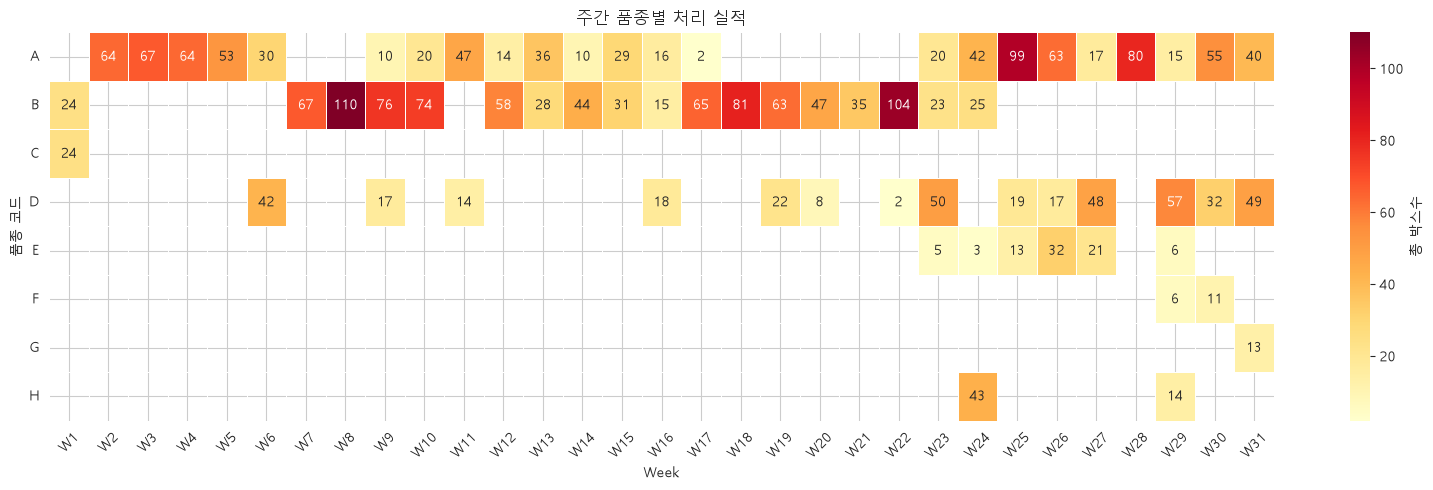

In [69]:
plt.figure(figsize=(16, 5))

sns.heatmap(
    heatmap_df,
    cmap='YlOrRd',          # 연한 노랑 ~ 진한 빨강
    annot=True,             # 숫자 표시
    fmt='.0f',              # 정수 형태
    linewidths=0.5,
    linecolor='white',
    mask=heatmap_df.isna(), # 작업 없는 주차는 빈칸 처리
    cbar_kws={'label': '총 박스수'}
)

plt.title('주간 품종별 처리 실적')
plt.xlabel('Week')
plt.ylabel('품종 코드')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

- 관찰 결과
    - 선별에 투입된 품종은 A~H 총 8가지
    - 드물게 투입된 품종과 여러 주차에 반복적으로 투입된 품종이 존재